In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

# %load_ext cuml.accel
# %load_ext cudf.pandas

'GPU: Tesla T4'

In [2]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [3]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import gc
import shutil
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR

from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import (StandardScaler, LabelEncoder, QuantileTransformer,
                                    KBinsDiscretizer, TargetEncoder as skTE)

from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

def seed_everything(seed: int):
    print(f"✓ Seed everything at {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

✓ Seed everything at 42


In [4]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})

# sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [5]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")
## =================================================================================
ID = 'id'
TARGET = 'is_fraud'

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


is_new_merchant                      2
is_fraud                             2
is_ai_generated_scam_attempt         2
billing_shipping_mismatch            2
ip_country_mismatch                  2
used_vpn                             2
is_foreign_transaction               2
cvv_retry_count                      4
auth_method                          5
prior_disputes                       5
card_type                            5
channel                              5
day_of_week                          7
device_type                          8
txn_count_last_24h                  12
merchant_category                   12
time_of_day_hour                    24
card_age_months                     49
customer_age                        64
velocity_score                     666
merchant_risk_score                950
hours_since_last_txn              3633
distance_from_home_km             4365
amount_usd                       13387
account_balance_usd              43317
id                       

In [6]:
# obj = train.select_dtypes(include=["object", "category"]).columns.tolist()
# bol = train.select_dtypes(include=[bool]).columns.tolist()

# cat_cols  = [c for c in obj if c not in [TARGET]]
# bool_cols = [c for c in bol if c not in [TARGET]]
# num_cols  = [c for c in train.columns if c not in cat_cols+bool_cols+[TARGET]]
# base_cols = [c for c in train.columns if c not in [TARGET]]

float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [8]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df.astype('float32'), on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [9]:
%%time
## NB: Original feature engineering

ID = 'id'
TARGET = 'is_fraud'

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

del train, test
print('-'*40)
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'bool']).columns.tolist()
base_cols = cat_cols + num_cols
print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
important_combos = [
    ('merchant_category', 'card_type', 'txn_count_last_24h'),
    ('merchant_category', 'customer_age'),
]
def feature_engineering(df, fit=False):
    # Digit extraction
    for col in ['amount_usd', 'hours_since_last_txn',
                'velocity_score', 'distance_from_home_km']:
        decimal_name = f"_{col}_decimal"
        df[decimal_name] = (df[col] % 1).round(2).astype('float32')

    # Categorize numericals
    for col in num_cols + ['_amount_usd_decimal', '_hours_since_last_txn_decimal',
                           '_velocity_score_decimal', '_distance_from_home_km_decimal']:
        cat_name = f"{col}_cat_" if col in num_cols else f"{col[1:]}_cat_"
        values = np.floor(df[col]) if col in num_cols else df[col]
        if fit:
            codes, uniques = values.factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = values.map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')

    # Discretize numericals
    bin_config = {'merchant_risk_score': [7], 'hours_since_last_txn': [500, 1000]}
    for col, bins_list in bin_config.items():
        for n_bins in bins_list:
            for strategy in ['quantile']:
                bin_name = f"{col}_{n_bins}_{strategy}_bin_"
                if fit:
                    kb = KBinsDiscretizer(
                        n_bins=n_bins,
                        encode='ordinal',
                        strategy=strategy,
                        subsample=None
                    )
                    binned = kb.fit_transform(df[[col]]).ravel().astype('int32')
                    category_map[bin_name] = kb
                else:
                    kb = category_map[bin_name]
                    binned = kb.transform(df[[col]]).ravel().astype('int32')
                df[bin_name] = binned
                df[bin_name] = df[bin_name].astype('category')

    # Create interaction categories
    combo_names = []
    for cols in important_combos:
        combo_name = '_'.join(cols) + '_'
        combo_names.append(combo_name)
        combo_series = df[cols[0]].astype(str)
        for col in cols[1:]:
            combo_series = combo_series + '_' + df[col].astype(str)
        if fit:
            codes, uniques = pd.factorize(combo_series, sort=False)
            category_map[combo_name] = uniques
        else:
            uniques = category_map[combo_name]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = combo_series.map(code_map).fillna(-1).astype('int32')
        df[combo_name] = codes
        df[combo_name] = df[combo_name].astype('category')

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols, combo_names

X, new_cat_cols, new_num_cols, combo_names = feature_engineering(X, fit=True)
X_test, _, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols
print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape, "\n")
print('-'*40)

----------------------------------------
X      init shape: (699960, 24)
X_test init shape: (299984, 24) 

init len(cat_cols): 11
init len(num_cols): 13 

len(new_cat_cols): 22
len(new_num_cols): 4 

prep len(cat_cols): 33
prep len(num_cols): 17 

X      prep shape: (699960, 50)
X_test prep shape: (299984, 50) 

----------------------------------------
CPU times: user 1.88 s, sys: 218 ms, total: 2.1 s
Wall time: 2.12 s


In [10]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    pd.concat([X, y], axis=1),
    train_size=100_000,
    stratify=y,
    random_state=42,
)

train_X = pd.concat([X, y], axis=1) if USE_FULL_TRAIN else x_sample.reset_index(drop=True)

print(train_X.shape, type(train_X))
train_X.head()

(699960, 51) <class 'pandas.core.frame.DataFrame'>


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,_amount_usd_decimal,_hours_since_last_txn_decimal,_velocity_score_decimal,_distance_from_home_km_decimal,amount_usd_cat_,hours_since_last_txn_cat_,txn_count_last_24h_cat_,distance_from_home_km_cat_,card_age_months_cat_,customer_age_cat_,account_balance_usd_cat_,cvv_retry_count_cat_,velocity_score_cat_,time_of_day_hour_cat_,day_of_week_cat_,merchant_risk_score_cat_,prior_disputes_cat_,amount_usd_decimal_cat_,hours_since_last_txn_decimal_cat_,velocity_score_decimal_cat_,distance_from_home_km_decimal_cat_,merchant_risk_score_7_quantile_bin_,hours_since_last_txn_500_quantile_bin_,hours_since_last_txn_1000_quantile_bin_,merchant_category_card_type_txn_count_last_24h_,merchant_category_customer_age_,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.16,0.77,0.5,0.78,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,371,553,0,0,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.83,0.54,0.4,0.06,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,2,80,104,1,1,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.36,0.20,0.8,0.17,2,1,2,2,2,2,2,0,2,2,2,1,0,2,2,2,2,1,59,79,2,2,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.44,0.13,0.7,0.67,3,2,2,2,0,3,3,0,3,3,0,2,0,3,3,3,3,5,251,338,3,3,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.85,0.80,0.8,0.69,4,3,2,3,3,4,4,0,4,4,3,3,0,4,4,2,4,5,42,54,4,4,0.0


In [11]:
## -- Handle optional original table aggregations --
USE_ORIGINAL = False

FEATURES = [c for c in train_X.columns if c not in [ID, TARGET]]
import_cols  = base_cols

if USE_ORIGINAL:
    aggs_ = ["mean"]  # "mean", "count", "std", "skew", "nunique",
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features = import_cols,
        aggs=aggs_, fill_nan=True
    )
    x_test, _ = original_TE(
        orig, X_test, target=TARGET, features = import_cols,
        aggs=aggs_, fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int32")
else:
    X = train_X[FEATURES]
    X_test = X_test[FEATURES]
    y = train_X[TARGET].astype("int32")

print(X.shape, type(X))
# X.head()

(699960, 50) <class 'pandas.core.frame.DataFrame'>


In [12]:
## -- Reduce data memory --
def reduce_memory(df):
    old_size = df.memory_usage(deep=True).sum() / (1024*1024)
    for c in tqdm(df.columns, desc='Reducing memory...'):
        if df[c].dtype == np.int64:
            ## -- Downcast Integer type ---
            if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
                df[c] = df[c].astype(np.int32)
                # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
                #     df[c] = df[c].astype(np.int16)
                #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
                #         df[c] = df[c].astype(np.int8)
        elif df[c].dtype == np.float64:
            ## -- Downcast Float type -----
            if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
                df[c] = df[c].astype(np.float32)
                # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
                #     df[c] = df[c].astype(np.float16)

    new_size = df.memory_usage(deep=True).sum() / (1024*1024)
    print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f}MB\n")

    return df

X = reduce_memory(X)
X_test = reduce_memory(X_test)
# orig = reduce_memory(orig)

print(f"Data memory reduced!")
gc.collect()

Reducing memory...:   0%|          | 0/50 [00:00<?, ?it/s]

Size before process: 292.5 MB
Size after process : 257.8MB



Reducing memory...:   0%|          | 0/50 [00:00<?, ?it/s]

Size before process: 125.4 MB
Size after process : 110.6MB

Data memory reduced!


42

In [13]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 50 columns):
 #   Column                                           Non-Null Count   Dtype   
---  ------                                           --------------   -----   
 0   amount_usd                                       699960 non-null  float32 
 1   hours_since_last_txn                             699960 non-null  float32 
 2   txn_count_last_24h                               699960 non-null  int32   
 3   distance_from_home_km                            699960 non-null  float32 
 4   card_age_months                                  699960 non-null  int32   
 5   customer_age                                     699960 non-null  int32   
 6   account_balance_usd                              699960 non-null  float32 
 7   cvv_retry_count                                  699960 non-null  int32   
 8   velocity_score                                   699960 non-null  float32 
 9   time

# ML TRAINING

In [14]:
# - PyTorch Dataset & FT-Transformer Architecture
class TabularDataset(Dataset):
    def __init__(self, x_cat, x_num, y=None):
        self.x_cat = torch.tensor(x_cat, dtype=torch.long)
        self.x_num = torch.tensor(x_num, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32) if y is not None else None

    def __len__(self):
        return len(self.x_num)

    def __getitem__(self, idx):
        if self.y is not None:
            return self.x_cat[idx], self.x_num[idx], self.y[idx]
        return self.x_cat[idx], self.x_num[idx]

class FTTransformer(nn.Module):
    def __init__(self, cat_dims, num_features, d_token=32, n_blocks=3, n_heads=4, ff_dropout=0.1):
        super().__init__()
        self.cat_dims = cat_dims
        self.num_features = num_features

        # Tokenize Categoricals
        self.cat_embeddings = nn.ModuleList([
            nn.Embedding(num_classes, d_token) for num_classes in cat_dims
        ])

        # Tokenize Numericals (each numerical feature gets multiplied by a learned weight vector to become d_token dim)
        self.num_embeddings = nn.Parameter(torch.randn(num_features, d_token))
        self.num_biases = nn.Parameter(torch.randn(num_features, d_token))

        # [CLS] Token (like in BERT, used for final classification)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_token))

        # Standard Transformer Encoder Blocks
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_token,
            nhead=n_heads,
            dim_feedforward=d_token * 2,
            dropout=ff_dropout,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_blocks)

        # Final prediction head
        self.head = nn.Sequential(
            nn.LayerNorm(d_token),
            nn.Linear(d_token, d_token // 2),
            nn.ReLU(),
            nn.Linear(d_token // 2, 1)
        )

    def forward(self, x_cat, x_num):
        batch_size = x_num.size(0)

        # 1. Process Categoricals
        cat_embs = []
        for i, emb in enumerate(self.cat_embeddings):
            cat_embs.append(emb(x_cat[:, i]).unsqueeze(1)) # Shape: (batch_size, 1, d_token)

        # 2. Process Numericals
        # x_num is (batch_size, num_features)
        # self.num_embeddings is (num_features, d_token)
        num_embs = x_num.unsqueeze(-1) * self.num_embeddings.unsqueeze(0) + self.num_biases.unsqueeze(0)

        # 3. Combine
        if len(cat_embs) > 0:
            cat_embs = torch.cat(cat_embs, dim=1)
            x = torch.cat([cat_embs, num_embs], dim=1) # Shape: (batch_size, num_cat + num_num, d_token)
        else:
            x = num_embs

        # 4. Add CLS Token
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1) # Shape: (batch_size, 1 + num_cat + num_num, d_token)

        # 5. Transformer Pass
        x = self.transformer(x)

        # 6. Extract CLS token output and classify
        cls_out = x[:, 0, :]
        return self.head(cls_out).squeeze(1)

print("PyTorch Dataset & FT-Transformer Architecture")

PyTorch Dataset & FT-Transformer Architecture


In [15]:
# full_df = pd.concat([X, X_test])
# for col in cat_cols:
#     l_enc = LabelEncoder()
#     l_enc.fit(full_df[col].astype(str))
#     X[col] = l_enc.transform(X[col].astype(str))
#     X_test[col] = l_enc.transform(X_test[col].astype(str))

# all_features = full_df.columns.tolist()
# cats_dict = { col: full_df[col].nunique() for col in all_cat_cols }

# cats_in_cols = [ f for f in all_cat_cols if f in all_features ]
# cat_idxs = [ all_features.index(f) for f in cats_in_cols ]
# cat_dims = [ cats_dict[f] for f in all_features if f in cats_in_cols ]

# print("cat_idxs:", cat_idxs)
# print("cat_dims:", cat_dims)

In [16]:
# 1. Print the table header once at the start of the fold
header = (
    "training | auc | best time | epoch"
)

print("+" * len(header))
print(header)
print("+" * len(header))

++++++++++++++++++++++++++++++++++
training | auc | best time | epoch
++++++++++++++++++++++++++++++++++


In [17]:
class CFG:
    TE = True if 'combo_names' in globals() else False
    FOLDS = 5
    SEED  = 42
    BATCH = 4096//2 if torch.cuda.is_available() else 128
    EPOCH = 10
    ES    = 5
    PREDICT_TEST = True

params = {
    'lr':     1e-3,
    'token':  32, # 32, 64, 96, 192... (⬆+32)
    'heads':  4,  # 4, 8
    'blocks': 3,
    'drop':   0.1,
    'wd':     0.0,
}

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = "torch_FTT_mlp"

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🚀 Training {model_name} with {FOLDS}-Folds | Device: {device}\n")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

all_cat_cols = list(set(cat_cols)) # ⚠️

fold_times = []
fold_scores = []
best_iterations = []
feat_importances = []

t0 = time()

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_trn, y_val = y.iloc[tr_idx].values, y.iloc[val_idx].values
    X_tst = X_test.copy()

    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    f0 = time()
    # Target encoding
    if CFG.TE:
        te_cols = combo_names + ['hours_since_last_txn']
        smooth = 'auto'
        print(f"⚡️ scikit_TE(smooth={smooth}) | features ({len(te_cols)})")
        TE = skTE(target_type='binary', cv=5, smooth='auto', random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE_{col}" for col in te_cols]
        X_trn[te_names]  = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = []
        X_trn  = X_trn.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)

    ## -- Get category label/dimensions --
    all_cats = [c for c in all_cat_cols if c not in combos_to_drop]

    cat_dims = []
    full_data = pd.concat([X_trn, X_val, X_tst])
    for c in all_cats:
        le = LabelEncoder().fit(full_data[c].astype(str))
        X_trn[c] = le.transform(X_trn[c].astype(str))
        X_val[c] = le.transform(X_val[c].astype(str))
        X_tst[c] = le.transform(X_tst[c].astype(str))
        cat_dims.append(len(le.classes_))

    if fold == 1:
        print(f"batch={CFG.BATCH}, train={X_trn.shape}, valid={X_val.shape}")
        print("Cats dims:", cat_dims) # dict(zip(all_cats, cat_dims))
    # ------------------------------------------------------------------------------
    X_tr_cat   = X_trn[all_cats]
    X_val_cat  = X_val[all_cats]
    X_test_cat = X_tst[all_cats]

    get_nums   = X_trn.columns.difference(all_cats, sort=False).tolist()
    X_tr_num   = X_trn[get_nums]
    X_val_num  = X_val[get_nums]
    X_test_num = X_tst[get_nums]

    qt = QuantileTransformer(output_distribution='normal', random_state=42)
    X_tr_num   = qt.fit_transform(X_tr_num)
    X_val_num  = qt.transform(X_val_num)
    X_test_num = qt.transform(X_test_num)

    train_dataset = TabularDataset(np.asarray(X_tr_cat), np.asarray(X_tr_num), y_trn)
    val_dataset   = TabularDataset(np.asarray(X_val_cat), np.asarray(X_val_num), y_val)
    test_dataset  = TabularDataset(np.asarray(X_test_cat), np.asarray(X_test_num))

    train_loader = DataLoader(train_dataset, batch_size=CFG.BATCH, shuffle=True)
    val_loader   = DataLoader(val_dataset, batch_size=CFG.BATCH, shuffle=False)
    test_loader  = DataLoader(test_dataset, batch_size=CFG.BATCH, shuffle=False)
    # ------------------------------------------------------------------------------

    model = FTTransformer(
        cat_dims=cat_dims,
        num_features=X_tr_num.shape[1],
        d_token=params['token'],
        n_blocks=params['blocks'],
        n_heads=params['heads'],
        ff_dropout=params['drop'],
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.AdamW(model.parameters(), lr=params['lr'], weight_decay=params['wd'])

    warmup_epochs = 2
    scheduler1 = LinearLR(optimizer, start_factor=0.1, total_iters=warmup_epochs)
    scheduler2 = CosineAnnealingLR(optimizer, T_max=CFG.EPOCH - warmup_epochs)
    scheduler  = SequentialLR(optimizer, schedulers=[scheduler1, scheduler2], milestones=[warmup_epochs])
    # ------------------------------------------------------------------------
    best_val_auc = 0
    best_epoch   = 0

    # 1. Print the table header once at the start of the fold
    header = ("training | epoch | val_loss | val_auc | best_auc")
    print("+" * len(header))
    print(header)
    print("+" * len(header))

    for epoch in range(CFG.EPOCH):
        model.train()
        train_loss = 0
        for b_cat, b_num, b_y in train_loader:
            b_cat, b_num, b_y = b_cat.to(device), b_num.to(device), b_y.to(device)

            optimizer.zero_grad()
            logits = model(b_cat, b_num)
            loss = criterion(logits, b_y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        # Calculate average training loss for the epoch
        avg_loss = train_loss / len(train_loader)

        scheduler.step()

        model.eval()
        val_preds = []
        val_targets = []
        with torch.no_grad():
            for b_cat, b_num, b_y in val_loader:
                b_cat, b_num = b_cat.to(device), b_num.to(device)
                logits = model(b_cat, b_num)
                val_preds.extend(torch.sigmoid(logits).cpu().numpy())
                val_targets.extend(b_y.cpu().numpy())

        val_auc = np.round(roc_auc_score(val_targets, val_preds), 5)
        # print(f"Epoch {epoch+1}/{CFG.EPOCH} AUC: {val_auc}")

        if val_auc > best_val_auc:
            best_epoch = epoch+1
            best_val_auc = val_auc
            torch.save(model.state_dict(), f"ft_fold_{fold}.pth")
            oof_preds[val_idx] = val_preds

        # 2. Format elapsed time (HH:MM:SS) using your existing `t0` timer
        elapsed_sec = int(time() - t0)
        hrs, rem = divmod(elapsed_sec, 3600)
        mins, secs = divmod(rem, 60)
        time_str = f"{hrs:02d}:{mins:02d}:{secs:02d}"

        print(
          f"{time_str} | {epoch+1:<5} | {avg_loss:<8.4f} | {val_auc:<7.5f} | {best_val_auc:.5f}"
        )

    fold_score = best_val_auc
    fold_scores.append(fold_score)
    best_iterations.append(best_epoch)
    # ------------------------------------------------------------------------
    model.load_state_dict(torch.load(f"ft_fold_{fold}.pth", weights_only=True))
    model.eval()
    fold_test_preds = []
    with torch.no_grad():
        for b_cat, b_num in test_loader:
            b_cat, b_num = b_cat.to(device), b_num.to(device)
            logits = model(b_cat, b_num)
            fold_test_preds.extend(torch.sigmoid(logits).cpu().numpy())

    test_preds += np.array(fold_test_preds)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)
    torch.cuda.empty_cache()

    print("-" * len(header))
    print(f"# Fold {fold} AUC: {Fore.YELLOW}{Style.BRIGHT}{fold_score}{Style.RESET_ALL}", end=' | ')
    print(f"[ epoch={best_epoch}, time={ff} mins ]\n")

test_preds /= FOLDS

model_name = model_name + f"({X_trn.shape[1]})"
features_used = X_trn.columns

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")

for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s}, epoch={t}")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
fold_results[f'epoch'] = best_iterations
fold_results[f'time(min)'] = fold_times

print("-"*50)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0)/60
print(f"{tt:.2f} mins\n")

del X_trn, X_val, y_trn, y_val, full_data, model

🚀 Training torch_FTT_mlp with 5-Folds | Device: cuda

### Fold 1/5
⚡️ scikit_TE(smooth=auto) | features (3)
batch=2048, train=(559968, 53), valid=(139992, 53)
Cats dims: [485, 2, 8, 50, 57, 2, 5, 51, 5, 24, 610, 1145, 2, 5, 2, 780, 100, 2, 11, 4929, 7, 64, 7, 100, 12, 4, 100, 5, 2, 98, 74, 768, 12]
++++++++++++++++++++++++++++++++++++++++++++++++
training | epoch | val_loss | val_auc | best_auc
++++++++++++++++++++++++++++++++++++++++++++++++
00:00:57 | 1     | 0.2868   | 0.64317 | 0.64317
00:01:27 | 2     | 0.0840   | 0.85600 | 0.85600
00:01:57 | 3     | 0.0549   | 0.93366 | 0.93366
00:02:26 | 4     | 0.0487   | 0.93938 | 0.93938
00:02:56 | 5     | 0.0469   | 0.94093 | 0.94093
00:03:25 | 6     | 0.0458   | 0.94200 | 0.94200
00:03:55 | 7     | 0.0449   | 0.94301 | 0.94301
00:04:24 | 8     | 0.0443   | 0.94354 | 0.94354
00:04:54 | 9     | 0.0438   | 0.94355 | 0.94355
00:05:23 | 10    | 0.0436   | 0.94355 | 0.94355
------------------------------------------------
# Fold 1 AUC: 0.94355 | 

In [18]:
# ==================================================
# 3-FOLD CV: torch_FTT_mlp(53) | (466640, 53)
# ==================================================
#  • Fold 1 AUC: 0.94162, epoch=5
#  • Fold 2 AUC: 0.94596, epoch=5
#  • Fold 3 AUC: 0.93737, epoch=5
# --------------------------------------------------
# OOF score: 0.94058
# AVG score: 0.94165 ± 0.00351
# --------------------------------------------------
# 7.87 mins

n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-' * 25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-' * 25)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

-------------------------
torch_FTT_mlp(53)_94475
-------------------------
26.9 mins



,auc,epoch,time(min)
fold 1,0.94355,9,5.47
fold 2,0.94374,9,5.34
fold 3,0.95094,10,5.35
fold 4,0.94547,10,5.34
fold 5,0.94006,10,5.34


In [19]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000344
1,699961,0.000315
2,699962,0.076277
3,699963,0.001531
4,699964,0.001062


In [20]:
# !rm -r /kaggle/working

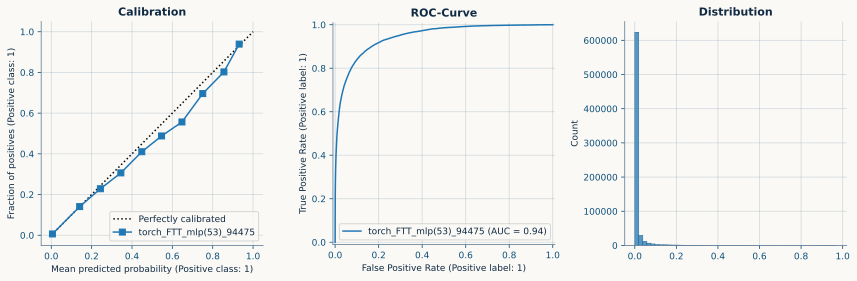

In [21]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout()
plt.show()

print()

In [22]:
# ## -- Feature Importances --
# top_n = 30

# imp_df = pd.Series(np.mean(feat_importances, axis=0), index=features_used).sort_values()[-top_n:]
# print(f"Total used features: {len(features_used)}\n")

# ax = imp_df.plot.barh(figsize=(12.5, len(imp_df)*0.25))
# ax.set_title(f"{n}: Avg. {FOLDS}-Fold importances", loc='left')
# ax.grid(True)

# plt.tight_layout()
# plt.show()